# Gauss-Bonnet with geomstats

The [**Atiyah-Singer Index Theorem**](https://en.wikipedia.org/wiki/Atiyah%E2%80%93Singer_index_theorem) is my favorite theorem in mathematics. It is a deep result that relates the topology of a manifold to the geometry of its curvature, through the index of a differential operator. This theorem is the reason I decided to do a PhD in the this area (see, [The 
$S^q$-Equivariant Signature for Semi-free Actions as an Index Formula](https://link.springer.com/article/10.1007/s12220-018-0088-1)). 

The first representation that I learned from this theorem is the [**Gauss-Bonnet theorem**](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem). This version of the index theorem relates the integral of the Gaussian curvature over a closed surface to the Euler characteristic of the surface. The firt proof that I studied of this result required careful triangulation of the surface, some detailed algebra and differential geometry on surfaces. It seemed a bit cumbersome, in my opinion. However, in the context of the index theorem, is it just a natural consequence. It is objectively beautiful.

In this notebook, I will describe how to understand the Gauss-Bonnet theorem by simply computing both sides of the equation numerically for a sphere, a torus, and an ellipsoid. We do not do this by hand, but rely in the amazing machinery developed by the [geomstats](https://github.com/geomstats/geomstats) library.

> Geomstats is a Python package for computations, statistics, machine learning and deep learning on manifolds.

This library has great abstractions of differential geometry concepts, and we can compute quantities that require derivatives, like curvatures (and higher order tensors) with automatic differentiation.

Many of their [examples](https://geomstats.github.io/tutorials/index.html) cover the basic concepts of differential geometry, and concrete real applications. Nevertheless, I think there is an opportunity to explore more deeper results and examples in the context of differential geometry and pure mathematics with this library.

## The Gauss-Bonnet Theorem in a Nutshell

- **The Geometry.** Take the unit sphere. Its Gaussian curvature is constant and equal to $1$ at every point. Since the surface area of the sphere is $4\pi$, this means that the integral of the curvature over the sphere is $4\pi$.

- **The Topology.** On the other hand, we can triangulate the sphere by projecting the edges of a cube onto the sphere from its center: the sphere splits into $6$ faces with $12$ edges and $8$ vertices. For such triangulation, we can compute the (somehow mysterious) quantity $8 - 12 + 6 = 2$.

The Gauss-Bonnet theorem says that these two numbers are linked on every closed surface: the integral of the Gaussian curvature equals $2\pi$ times the number of vertices minus edges plus faces. For the sphere this is $4\pi = 2\pi \cdot 2$. The count, called the [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic), does not depend on how we cut the surface into polygons.

On other surfaces the integral of the curvature is harder to compute. The curvature changes from point to point, and computing it from the metric alone, that is, from lengths measured on the surface, needs derivatives of a parametrization up to the third order. By hand this is long and error-prone, and a numerical integral needs care where the parametrization degenerates, such as at the poles of a sphere.

In this notebook we compute both sides of the theorem numerically for a sphere, a torus, and an ellipsoid, and check that they agree. We describe each surface by a parametrization, and geomstats derives the metric and the curvature from it with the automatic differentiation of PyTorch. For the right side we take a grid on the parameter rectangle, glue its edges the way the surface closes up, and count its vertices, edges, and faces.

We keep the setting simple on purpose:

- **Closed surfaces:** Our surfaces have no boundary, so the boundary term of the general theorem does not appear.

- **One chart per surface:** We parametrize each surface over one rectangle whose edges are either glued or collapsed to points.

- **Surfaces in $\mathbb{R}^3$:** The metric of each surface is the one induced by the Euclidean space around it.

We assume you know the basic objects of the differential geometry of surfaces (first fundamental form, Gaussian curvature) at the level of [do Carmo](https://store.doverpublications.com/products/9780486806990) , and that you have used automatic differentiation in PyTorch.

The main references used in this notebook are:

- **Theory:** [do Carmo](https://store.doverpublications.com/products/9780486806990) for the differential geometry of surfaces and the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem).

- **Software:** [geomstats](https://github.com/geomstats/geomstats) ([Miolane et al.](https://jmlr.org/papers/v21/19-027.html)), which computes the curvature of a parametrized surface with automatic differentiation.

- **Quadrature:** [Trefethen and Weideman](https://doi.org/10.1137/130932132) on the trapezoidal rule for periodic integrands.



## Prepare Notebook

We select the backend of geomstats with the `GEOMSTATS_BACKEND` environment variable before the first import, because geomstats reads it only then. We also load the jaxtyping extension, so that beartype checks the shapes in our type annotations at run time (see *Base Class*).

In [1]:
%env GEOMSTATS_BACKEND=pytorch

env: GEOMSTATS_BACKEND=pytorch


In [2]:
import math
from collections.abc import Callable
from enum import StrEnum
from typing import NamedTuple

import arviz as az
import geomstats.backend as gs
import matplotlib.pyplot as plt
import torch
from geomstats.geometry.base import ImmersedSet
from geomstats.geometry.euclidean import Euclidean
from jaxtyping import Float, Int
from matplotlib.colors import CenteredNorm
from numpy.polynomial.legendre import leggauss
from torch import Tensor

seed: int = 42
rng: torch.Generator = torch.Generator().manual_seed(seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

We check that geomstats uses the PyTorch backend and that PyTorch creates tensors in double precision, the default that geomstats sets on import. We need double precision because the checks below compare curvatures at round-off level, below $10^{-12}$, far below the round-off of single precision.

In [3]:
assert gs.__name__ == "geomstats.pytorch"
assert torch.get_default_dtype() == torch.float64

Now that we compute in double precision, we can state the theorem.

## The Gauss-Bonnet Theorem

Let $M$ be a compact, oriented, two-dimensional Riemannian manifold with a smooth (possibly empty) boundary $\partial M$. We use the following notation:

- $K$ is the **Gaussian curvature** of $M$ and $dA$ is its **area element**.
- $k_g$ is the **geodesic curvature** of the boundary and $ds$ is the arc length along it.
- $\chi(M) = V - E + F$ is the **Euler characteristic** of $M$, where $V$, $E$, and $F$ are the numbers of vertices, edges, and faces of any polygonal decomposition of $M$ (see [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)).

With this notation, the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem) states that

$$
\int_M K \, dA + \int_{\partial M} k_g \, ds = 2 \pi \chi(M).
$$

When $M$ is closed, that is, compact and without boundary, the boundary term is absent:

$$
\int_M K \, dA = 2 \pi \chi(M).
$$

This is the case we treat here. The left side depends only on the metric of the surface, which measures lengths inside it. The right side depends only on its topology.

Why does the right side not depend on the polygonal decomposition? The Euler characteristic equals the alternating sum of the [Betti numbers](https://en.wikipedia.org/wiki/Betti_number) $b_k$ of $M$, the ranks of its singular homology groups (see the section "Betti number alternative" of [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)). On a surface $b_k = 0$ for $k > 2$, so

$$
\chi(M) = b_0 - b_1 + b_2.
$$

Homology is a topological invariant (see the section "Homotopy invariance" of the same article). Hence $\chi$ is a topological invariant too, and every polygonal decomposition of $M$ gives the same value of $V - E + F$.

Here is an important observation about the implications of the Gauss-Bonnet theorem: when we deform a surface smoothly, the values of $K$ and $dA$ at each point change, but the integral of $K \, dA$ stays the same.

**Examples.**

- For a closed orientable surface, the Euler characteristic is $\chi = 2 - 2 \, \text{genus}$, where the genus is the number of holes (see the section "Relations to other invariants" of [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)). The sphere has the Betti numbers $1, 0, 1$ and genus $0$, so $\chi = 2$. The torus has the Betti numbers $1, 2, 1$ and genus $1$, so $\chi = 0$.

- A sphere of radius $\rho$ has constant curvature $K = 1 / \rho^2$ and area $4 \pi \rho^2$, so its total curvature, the integral of $K \, dA$, is $4 \pi = 2 \pi \cdot 2$ for every radius. The curvature of a torus is positive on the outer half and negative on the inner half, and the two parts cancel.

To compute the left side on other surfaces, we need $K$ in the coordinates of a parametrization.

## Curvature in Coordinates

We describe a surface by an **immersion** $f: U \to \mathbb{R}^3$ of a parameter domain $U \subset \mathbb{R}^2$, written $(u, v) \mapsto f(u, v)$. We write $\partial_i$ for the partial derivative with respect to the coordinate $i \in \{u, v\}$, and we sum over repeated indices. Every object below is a function on $U$ built from derivatives of $f$.

The **pullback metric**, also called the first fundamental form, is the matrix of inner products of the first derivatives of $f$,

$$
g_{ij} = \langle \partial_i f, \partial_j f \rangle,
$$

and the area element is $dA = \sqrt{\det g} \, du \, dv$. We write $g^{ij}$ for the entries of the inverse matrix $g^{-1}$.

The **Christoffel symbols** of the Levi-Civita connection $\nabla$ need the first derivatives of $g$, which are second derivatives of $f$:

$$
\Gamma^k_{ij} = \frac{1}{2} g^{kl} \left( \partial_i g_{jl} + \partial_j g_{il} - \partial_l g_{ij} \right).
$$

The **Riemann curvature tensor** needs the first derivatives of $\Gamma$, which are third derivatives of $f$. In the index convention of geomstats it reads

$$
R^l_{ijk} = \partial_j \Gamma^l_{ki} - \partial_k \Gamma^l_{ji} + \Gamma^l_{jm} \Gamma^m_{ki} - \Gamma^l_{km} \Gamma^m_{ji}.
$$

For vector fields $X$, $Y$, $Z$ on $U$ with Lie bracket $[X, Y]$, these are the components of the curvature map $R(X, Y) Z = \nabla_X \nabla_Y Z - \nabla_Y \nabla_X Z - \nabla_{[X, Y]} Z$ in coordinates, $R(\partial_j, \partial_k) \partial_i = R^l_{ijk} \partial_l$. Textbooks differ in the sign and the index order of $R$, so we use the convention of geomstats throughout.

A surface has a single tangent plane at each point, and its Gaussian curvature is the **sectional curvature** of that plane. In coordinates,

$$
K = \frac{\langle R(\partial_u, \partial_v) \partial_v, \partial_u \rangle}{g_{uu} g_{vv} - g_{uv}^2} = \frac{g_{ul} R^l_{vuv}}{\det g},
$$

where the inner product is the one given by $g$. This is the **intrinsic** route to $K$, because it only uses $g$ and its derivatives.

There is also an **extrinsic** route. It uses the unit normal $N$ and the **second fundamental form** $h$,

$$
N = \frac{\partial_u f \times \partial_v f}{\| \partial_u f \times \partial_v f \|}, \qquad h_{ij} = \langle \partial_i \partial_j f, N \rangle, \qquad K = \frac{\det h}{\det g}.
$$

Here are two important remarks. First, the extrinsic route needs second derivatives of $f$, while the intrinsic route needs third derivatives. Second, Gauss's [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium) says that both routes give the same $K$.

Its Wikipedia article states the theorem and its consequence for bending as follows:

> The theorem says that Gaussian curvature can be determined entirely by measuring angles, distances and their rates of change on a surface, without reference to the particular manner in which the surface is embedded in the ambient 3-dimensional Euclidean space. In other words, the Gaussian curvature of a surface does not change if one bends the surface without stretching it. Thus the Gaussian curvature is an intrinsic invariant of a surface.

Bending keeps the lengths on the surface, so it keeps $g$, and the intrinsic route computes $K$ from $g$ alone. We compare both routes in *Curvature Checks*, after we see how geomstats computes each of these objects.

## Surfaces in geomstats

In geomstats, a parametrized manifold is an `ImmersedSet`. Its points are intrinsic coordinates $(u, v)$, and a subclass implements the method `immersion`, which is our $f$. The default metric of an `ImmersedSet` is a `PullbackMetric`, whose methods compute the objects of *Curvature in Coordinates*.

### Derivative Chain

The metric computes these objects in four steps:

1. **Metric.** `jacobian_immersion` differentiates `immersion` once, and `metric.metric_matrix` builds $g$ from the Jacobian.
2. **Christoffel symbols.** `hessian_immersion` differentiates `immersion` twice, `metric.inner_product_derivative_matrix` builds $\partial_k g_{ij}$ from the Jacobian and the Hessian, and `metric.christoffels` builds $\Gamma$.
3. **Riemann tensor.** `metric.riemann_tensor` differentiates `metric.christoffels` once more and assembles $R$.
4. **Sectional curvature.** `metric.sectional_curvature` contracts $R$ with two tangent vectors and divides by $g_{uu} g_{vv} - g_{uv}^2$.

Three conventions matter when we read these arrays:

- **Christoffel symbols:** The contravariant index comes first, so `christoffels[..., k, i, j]` is $\Gamma^k_{ij}$.
- **Riemann tensor:** The contravariant index comes last, so `riemann_tensor[..., i, j, k, l]` is $R^l_{ijk}$.
- **Hessian:** The indices of differentiation come last, so `hessian_immersion[..., :, i, j]` is the vector $\partial_i \partial_j f$.

In the PyTorch backend, `gs.autodiff.jacobian_vec` and `gs.autodiff.hessian_vec` loop over the points and call `torch.autograd.functional.jacobian` and `torch.autograd.functional.hessian` with `create_graph=point.requires_grad` (see [`autodiff.py`](https://github.com/geomstats/geomstats/blob/1b42ec9fa9879cdfedf79cadc5adaeca300bf51b/geomstats/_backend/pytorch/autodiff.py)). PyTorch sets `requires_grad` on the inputs it differentiates, so the Jacobian and the Hessian of step $2$ keep their computational graph exactly when the outer derivative of step $3$ needs it. The loops over points also set the cost, which grows linearly with the number of points at which we evaluate $K$.

Before [#2142](https://github.com/geomstats/geomstats/pull/2142), the PyTorch backend dropped the graph of the inner derivatives, so the derivative of $\Gamma$ in step $3$ was zero and the intrinsic $K$ was wrong without a warning. This affects the `2.8.0` release: the pull request reports $2.14$ and $-0.66$ at two test points instead of $1$ for the unit sphere.

### Base Class

To integrate and to count, we also need to know how the parameter rectangle $U = [u_{\min}, u_{\max}] \times [v_{\min}, v_{\max}]$ closes up into the surface. A **closure** describes one parameter direction:

- **Periodic:** The two opposite edges are glued, as for an angle.
- **Pole:** Each of the two edges collapses to a single point, as for the polar angle of a sphere.

The quadrature rule of the left side and the glued grid of the right side both depend on the closures. The base class `ClosedSurface` stores them with the parameter ranges, and adds the area element and the two routes to $K$.

We annotate every tensor with its shape using [jaxtyping](https://docs.kidger.site/jaxtyping/). For example, `Float[Tensor, "n_points 2"]` is a batch of points in the parameter rectangle, and `Float[Tensor, " n_points"]` holds one value per point. [beartype](https://github.com/beartype/beartype) checks the arguments and the return values of every function and method at run time, so a tensor of the wrong shape fails where it enters or leaves a function. The fields of a `NamedTuple` only document their shapes.

In [4]:
class Closure(StrEnum):
    """How one parameter direction of the rectangle closes up."""

    PERIODIC = "periodic"
    POLE = "pole"


class ClosedSurface(ImmersedSet):
    """Closed surface in R^3 parametrized over a rectangle.

    Subclasses set the class attributes below and implement `immersion`.

    Attributes
    ----------
    domain : tuple[tuple[float, float], tuple[float, float]]
        Parameter ranges ((u_min, u_max), (v_min, v_max)).
    closures : tuple[Closure, Closure]
        How each parameter direction closes up.
    """

    domain: tuple[tuple[float, float], tuple[float, float]]
    closures: tuple[Closure, Closure]

    def __init__(self) -> None:
        super().__init__(dim=2)

    def _define_embedding_space(self) -> Euclidean:
        return Euclidean(dim=3)

    def area_element(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Area element sqrt(det g)."""
        return torch.linalg.det(self.metric.metric_matrix(points)).sqrt()

    def gaussian_curvature(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Intrinsic K, the sectional curvature of the coordinate plane."""
        d_u, d_v = torch.eye(2)
        return self.metric.sectional_curvature(d_u, d_v, points)

    def gaussian_curvature_extrinsic(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Extrinsic K = det(h) / det(g) with h_ij = <d_i d_j f, N>."""
        d_u_f, d_v_f = self.jacobian_immersion(points).unbind(dim=-1)
        normal = torch.linalg.cross(d_u_f, d_v_f)
        normal = normal / torch.linalg.vector_norm(normal, dim=-1, keepdim=True)
        h = torch.einsum("...aij,...a->...ij", self.hessian_immersion(points), normal)
        return torch.linalg.det(h) / torch.linalg.det(self.metric.metric_matrix(points))

### Surface Immersions

Each surface is a subclass of `ClosedSurface` that sets `domain` and `closures`, implements `immersion`, and gives the closed form of $K$, which we use only as a check.

#### Sphere

The sphere of radius $\rho$ uses as its coordinates $(u, v)$ the polar angle $\theta \in [0, \pi]$, which ends at two poles, and the periodic azimuth $\varphi \in [0, 2\pi]$:

$$
f(\theta, \varphi) = \rho \left( \sin\theta \cos\varphi, \; \sin\theta \sin\varphi, \; \cos\theta \right).
$$

Its curvature is constant, $K = 1 / \rho^2$.

The class `Sphere` implements this immersion and this closed form:

In [5]:
class Sphere(ClosedSurface):
    """Sphere with polar angle theta in [0, pi] and azimuth phi in [0, 2 pi].

    Parameters
    ----------
    radius : float
        Radius rho of the sphere.
    """

    domain = ((0.0, torch.pi), (0.0, 2 * torch.pi))
    closures = (Closure.POLE, Closure.PERIODIC)

    def __init__(self, radius: float) -> None:
        self.radius = radius
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        theta, phi = point.unbind(dim=-1)
        return self.radius * torch.stack(
            [
                torch.sin(theta) * torch.cos(phi),
                torch.sin(theta) * torch.sin(phi),
                torch.cos(theta),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K = 1 / rho^2, used as a check."""
        return torch.full(points.shape[:-1], 1 / self.radius**2)

#### Torus

The torus with major radius $D$ (the distance from the center of the tube to the axis) and minor radius $r$ uses the angle $u$ around the tube and the angle $v$ around the hole, and both are periodic:

$$
f(u, v) = \left( (D + r \cos u) \cos v, \; (D + r \cos u) \sin v, \; r \sin u \right).
$$

Its curvature is $K = \cos u / \left( r (D + r \cos u) \right)$.

The class `Torus` implements this immersion and this closed form:

In [6]:
class Torus(ClosedSurface):
    """Ring torus with angle u around the tube and angle v around the hole.

    Parameters
    ----------
    major_radius : float
        Distance D from the center of the tube to the axis of the torus.
    minor_radius : float
        Radius r of the tube.
    """

    domain = ((0.0, 2 * torch.pi), (0.0, 2 * torch.pi))
    closures = (Closure.PERIODIC, Closure.PERIODIC)

    def __init__(self, major_radius: float, minor_radius: float) -> None:
        self.major_radius, self.minor_radius = major_radius, minor_radius
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        u, v = point.unbind(dim=-1)
        distance_to_axis = self.major_radius + self.minor_radius * torch.cos(u)
        return torch.stack(
            [
                distance_to_axis * torch.cos(v),
                distance_to_axis * torch.sin(v),
                self.minor_radius * torch.sin(u),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K, used as a check."""
        u, _ = points.unbind(dim=-1)
        distance_to_axis = self.major_radius + self.minor_radius * torch.cos(u)
        return torch.cos(u) / (self.minor_radius * distance_to_axis)

#### Ellipsoid

The ellipsoid stretches the sphere along its three axes. With semi-axes $a$, $b$, $c$, it uses the same coordinates as the sphere:

$$
f(\theta, \varphi) = \left( a \sin\theta \cos\varphi, \; b \sin\theta \sin\varphi, \; c \cos\theta \right).
$$

[MathWorld](https://mathworld.wolfram.com/Ellipsoid.html) gives its curvature at the point $(x, y, z) = f(\theta, \varphi)$,

$$
K = \frac{1}{a^2 b^2 c^2 \left( x^2 / a^4 + y^2 / b^4 + z^2 / c^4 \right)^2}.
$$

The sphere of radius $\rho$ is the case $a = b = c = \rho$, and the formula then gives $K = 1 / \rho^2$.

The class `Ellipsoid` implements this immersion and the closed form of MathWorld:

In [7]:
class Ellipsoid(ClosedSurface):
    """Ellipsoid with polar angle theta in [0, pi] and azimuth phi in [0, 2 pi].

    Parameters
    ----------
    a, b, c : float
        Semi-axes along x, y, and z.
    """

    domain = ((0.0, torch.pi), (0.0, 2 * torch.pi))
    closures = (Closure.POLE, Closure.PERIODIC)

    def __init__(self, a: float, b: float, c: float) -> None:
        self.a, self.b, self.c = a, b, c
        super().__init__()

    def immersion(self, point: Float[Tensor, "*batch 2"]) -> Float[Tensor, "*batch 3"]:
        theta, phi = point.unbind(dim=-1)
        return torch.stack(
            [
                self.a * torch.sin(theta) * torch.cos(phi),
                self.b * torch.sin(theta) * torch.sin(phi),
                self.c * torch.cos(theta),
            ],
            dim=-1,
        )

    def gaussian_curvature_closed_form(
        self, points: Float[Tensor, "n_points 2"]
    ) -> Float[Tensor, " n_points"]:
        """Closed-form K, used as a check."""
        x, y, z = self.immersion(points).unbind(dim=-1)
        a, b, c = self.a, self.b, self.c
        return 1 / (a * b * c * (x**2 / a**4 + y**2 / b**4 + z**2 / c**4)) ** 2

Next, let's check the curvature of the three surfaces.

## Curvature Checks

Before we integrate anything, we check $K$ pointwise, because an error in an index convention or in a nested derivative would show up here. We take the unit sphere, the torus with $D = 2$ and $r = 0.7$, and the ellipsoid with semi-axes $a = 1$, $b = 1.5$, and $c = 0.6$. For each surface we draw $20$ random points in the parameter rectangle and compute $K$ in three ways: the intrinsic route, the closed form, and the extrinsic route.

In [8]:
surfaces: dict[str, Sphere | Torus | Ellipsoid] = {
    "sphere": Sphere(radius=1.0),
    "torus": Torus(major_radius=2.0, minor_radius=0.7),
    "ellipsoid": Ellipsoid(a=1.0, b=1.5, c=0.6),
}


def random_points(
    surface: ClosedSurface, n_points: int, generator: torch.Generator
) -> Float[Tensor, "n_points 2"]:
    """Points drawn uniformly from the parameter rectangle of the surface."""
    low, high = torch.tensor(surface.domain).T
    return low + (high - low) * torch.rand(n_points, 2, generator=generator)


class CurvatureErrors(NamedTuple):
    """Largest absolute difference between the intrinsic K and each reference."""

    closed_form: float
    extrinsic: float


def curvature_errors(
    surface: Sphere | Torus | Ellipsoid, points: Float[Tensor, "n_points 2"]
) -> CurvatureErrors:
    """Compare the intrinsic K with the closed form and the extrinsic route."""
    intrinsic = surface.gaussian_curvature(points)
    closed_form = surface.gaussian_curvature_closed_form(points)
    extrinsic = surface.gaussian_curvature_extrinsic(points)
    return CurvatureErrors(
        closed_form=(intrinsic - closed_form).abs().max().item(),
        extrinsic=(intrinsic - extrinsic).abs().max().item(),
    )


CURVATURE_TOLERANCE = 1e-12

curvature_check = {
    name: curvature_errors(surface, random_points(surface, n_points=20, generator=rng))
    for name, surface in surfaces.items()
}

assert all(max(errors) < CURVATURE_TOLERANCE for errors in curvature_check.values())

We plot the largest absolute difference between the intrinsic $K$ and each reference on a log axis:

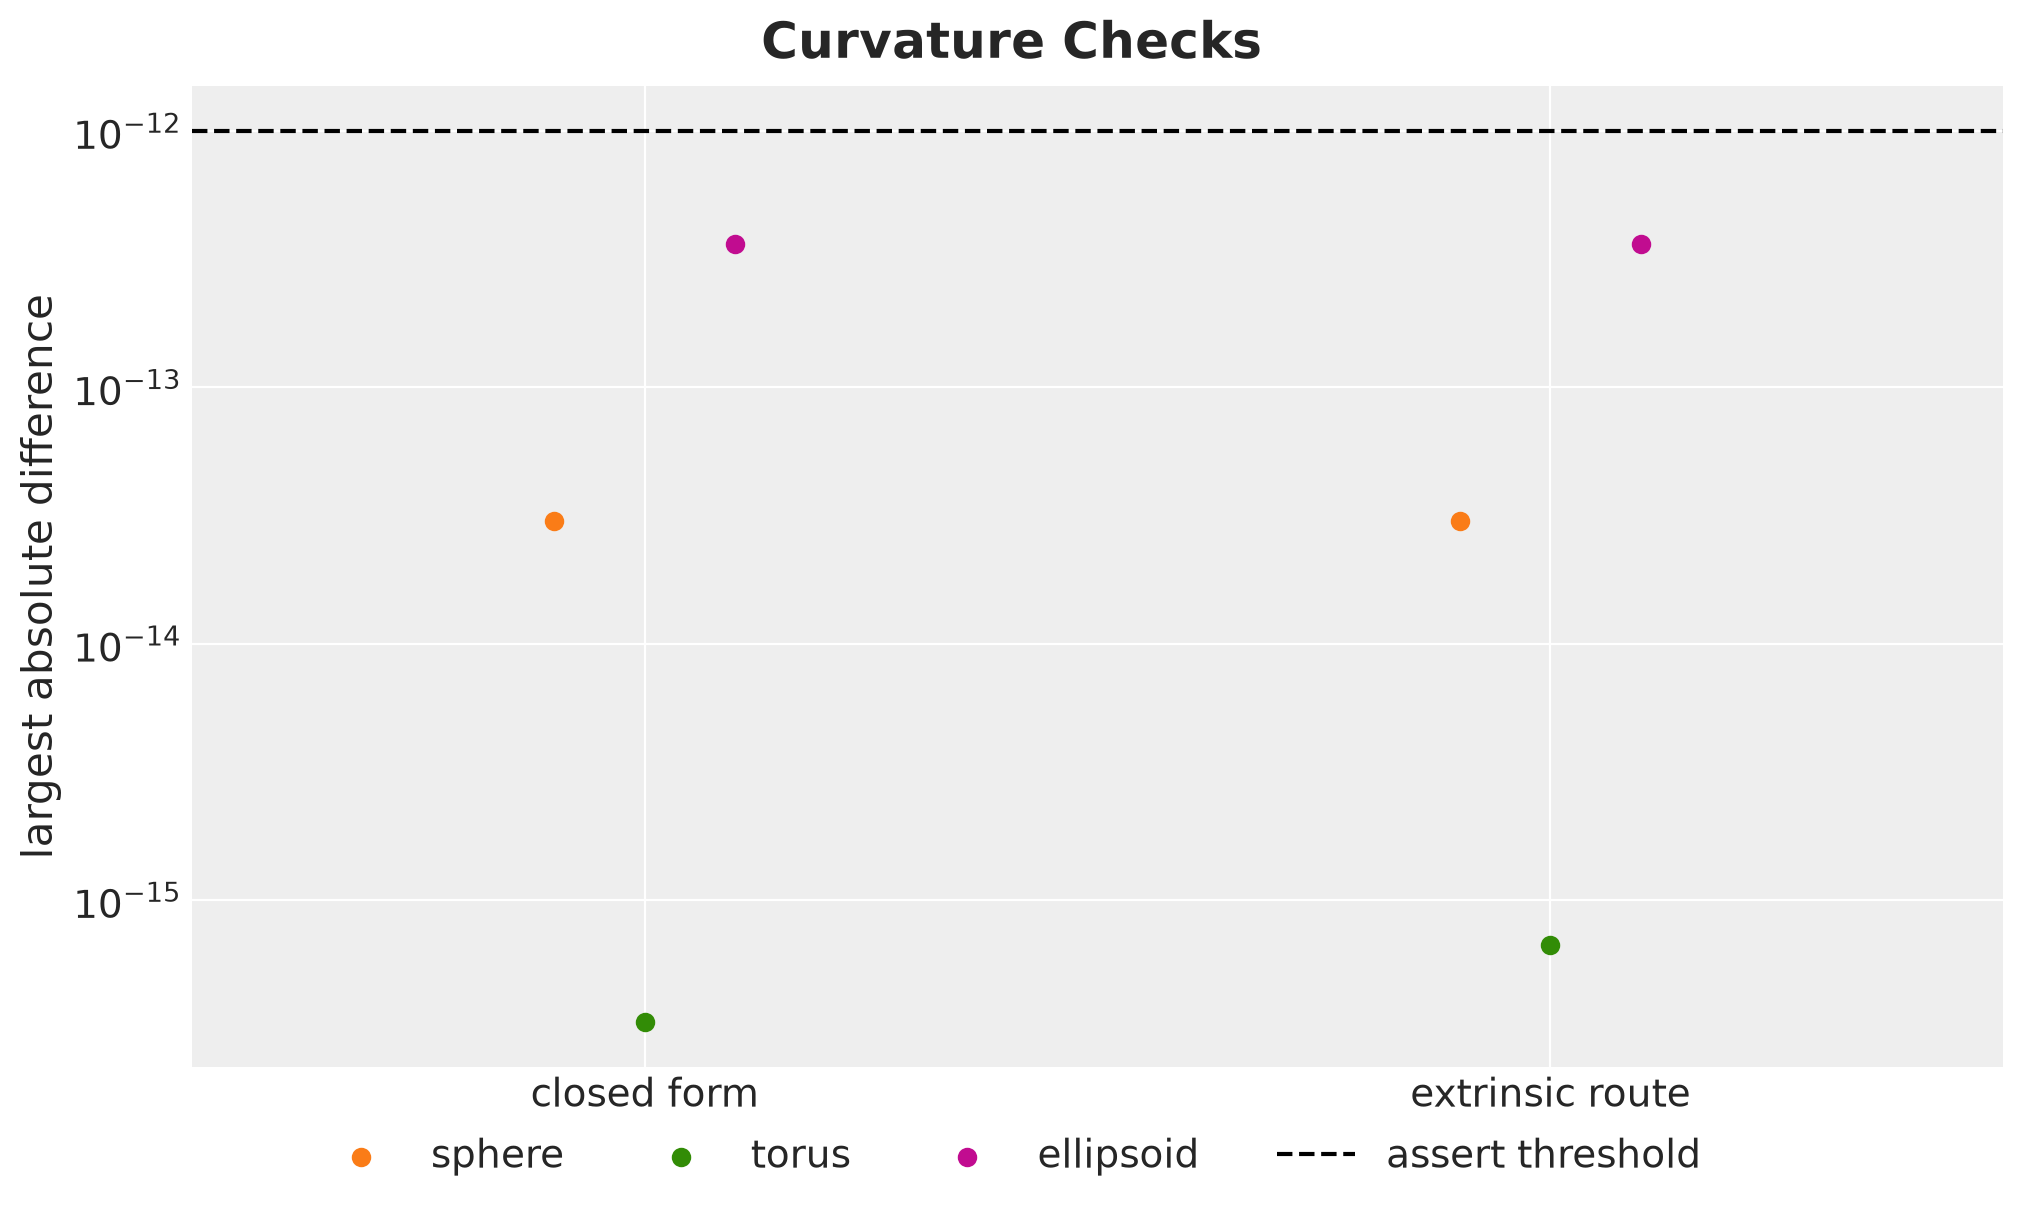

In [9]:
SURFACE_COLORS = {"sphere": "C1", "torus": "C2", "ellipsoid": "C3"}
REFERENCE_LABELS = {"closed_form": "closed form", "extrinsic": "extrinsic route"}

fig, ax = plt.subplots(layout="constrained")
positions = torch.arange(len(CurvatureErrors._fields))

for offset, (name, color) in zip((-0.1, 0.0, 0.1), SURFACE_COLORS.items(), strict=True):
    ax.scatter(positions + offset, curvature_check[name], color=color, label=name)

ax.axhline(CURVATURE_TOLERANCE, color="black", linestyle="--", label="assert threshold")
ax.set(
    yscale="log",
    xticks=positions,
    xticklabels=[REFERENCE_LABELS[field] for field in CurvatureErrors._fields],
    xlim=(-0.5, len(positions) - 0.5),
    ylabel="largest absolute difference",
)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Curvature Checks", fontsize=18, fontweight="bold");

All differences are at round-off level and below the threshold. The closed form checks the whole intrinsic route, including the nested derivative of step $3$, and the extrinsic route checks the Theorema Egregium at these points: the second and the third derivatives of $f$ give the same curvature.

Now that we trust $K$, let's look at how it varies over each surface.

## Curvature Maps

We evaluate the intrinsic $K$ at the centers of a uniform $24 \times 24$ grid on the parameter rectangle of each surface. This takes a while, because each point needs its own Riemann tensor.

In [10]:
%%time


def tensor_grid(
    u: Float[Tensor, " n_u"], v: Float[Tensor, " n_v"]
) -> Float[Tensor, "n_u n_v 2"]:
    """All pairs (u_p, v_q) of the two coordinates, on a grid indexed by (p, q)."""
    return torch.stack(torch.meshgrid(u, v, indexing="ij"), dim=-1)


class CurvatureMap(NamedTuple):
    """Surface points on a grid of the parameter rectangle and K at the cell centers."""

    surface_points: Float[Tensor, "n_vertices n_vertices 3"]
    curvature: Float[Tensor, "n_cells n_cells"]


def curvature_map(surface: ClosedSurface, n_cells: int = 24) -> CurvatureMap:
    """Evaluate the surface on a uniform grid and K at the cell centers."""
    u_vertices, v_vertices = (
        torch.linspace(lower, upper, n_cells + 1) for lower, upper in surface.domain
    )
    vertices = tensor_grid(u_vertices, v_vertices)
    centers = (vertices[:-1, :-1] + vertices[1:, 1:]) / 2
    # The metric methods of geomstats expect a flat batch of points.
    curvature = surface.gaussian_curvature(centers.reshape(-1, 2))
    return CurvatureMap(
        surface_points=surface.immersion(vertices),
        curvature=curvature.reshape(n_cells, n_cells),
    )


curvature_maps = {name: curvature_map(surface) for name, surface in surfaces.items()}

CPU times: user 19.2 s, sys: 153 ms, total: 19.4 s
Wall time: 19.4 s


We color each cell of a surface by its value of $K$. The colormap is centered at $K = 0$, so red cells have positive and blue cells negative curvature.

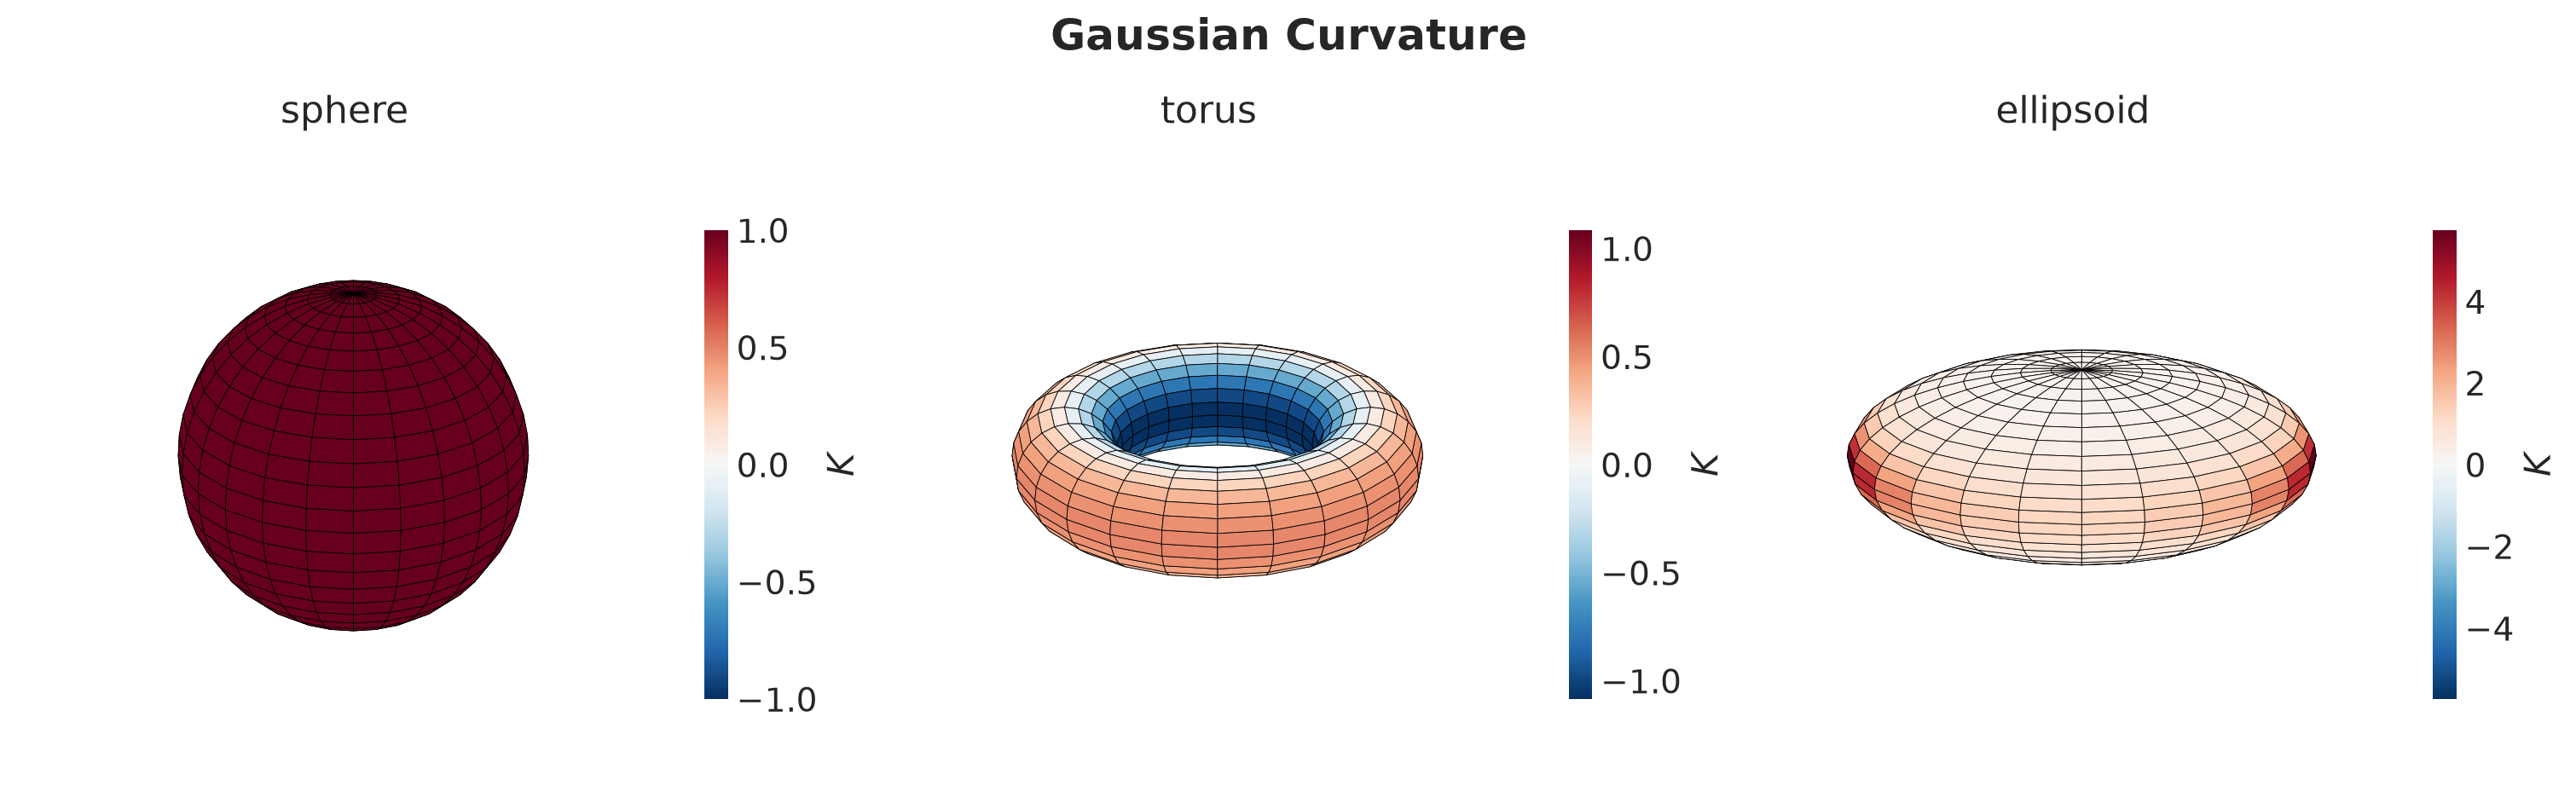

In [11]:
cmap = plt.colormaps["RdBu_r"]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), subplot_kw={"projection": "3d"}, layout="constrained"
)

for ax, (name, curvature_map_) in zip(axes, curvature_maps.items(), strict=True):
    norm = CenteredNorm()
    ax.plot_surface(
        *curvature_map_.surface_points.unbind(dim=-1),
        facecolors=cmap(norm(curvature_map_.curvature)),
        edgecolor="black",
        linewidth=0.3,
        shade=False,
    )
    ax.set_aspect("equal")
    ax.view_init(elev=25, azim=0)
    ax.set_axis_off()
    ax.set_facecolor("white")
    ax.set_title(name)
    fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label="$K$"
    )

fig.suptitle("Gaussian Curvature", fontsize=18, fontweight="bold");

The colors show where each surface curves:

- **Sphere.** It has a single color because its curvature is constant.
- **Torus.** It is red on the outer half and blue on the inner half, the two parts that cancel in its total curvature. From the closed form, the inner half is more curved, down to $-1 / \left( r (D - r) \right) \approx -1.10$ against up to $1 / \left( r (D + r) \right) \approx 0.53$, but it has less area.
- **Ellipsoid.** It is red near the two ends of its longest axis and almost white elsewhere, so its curvature is concentrated near these ends. The closed form gives $K = b^2 / (a^2 c^2) = 6.25$ there, and the colorbar stops below that value because the cell centers miss the ends.

Next, let's integrate $K$ over each surface.

## Total Curvature

We now turn to the left side of the theorem. Over the parameter rectangle, the total curvature is

$$
\int_M K \, dA = \int_{u_{\min}}^{u_{\max}} \int_{v_{\min}}^{v_{\max}} K(u, v) \sqrt{\det g(u, v)} \, dv \, du.
$$

We take nodes $u_p$ with weights $\alpha_p$ in the first direction and nodes $v_q$ with weights $\beta_q$ in the second direction, for $p, q = 1, \ldots, n$, and approximate the integral by the tensor-product sum

$$
\int_M K \, dA \approx \sum_{p=1}^{n} \sum_{q=1}^{n} \alpha_p \beta_q \, K(u_p, v_q) \sqrt{\det g(u_p, v_q)}.
$$

The one-dimensional rule follows the closure. In a periodic direction we use the composite midpoint rule, which for a periodic integrand is the trapezoidal rule on a grid shifted by half a step. [Trefethen and Weideman](https://doi.org/10.1137/130932132) open their review of this rule with the following sentence:

> It is well known that the trapezoidal rule converges geometrically when applied to analytic functions on periodic intervals or the real line.

In a direction that ends at poles, let $\psi(\theta)$ be the integrand as a function of the polar angle $\theta \in [0, \pi]$ at a fixed azimuth. It is smooth but not periodic. With step $\delta = \pi / n$, the [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula) gives the leading error term of the midpoint rule:

$$
\frac{\delta^2}{24} \left( \psi'(\pi) - \psi'(0) \right).
$$

On our ellipsoids $K > 0$ and $\sqrt{\det g}$ vanishes like $\sin\theta$ at each pole, so $\psi'(0) > 0 > \psi'(\pi)$. The term does not vanish, and the error decays only as $n^{-2}$.

There we use [Gauss-Legendre nodes](https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature) instead, which converge geometrically in $n$ for an integrand that is analytic around the interval (Theorem $4.5$ in [Trefethen](https://doi.org/10.1137/060659831)). Both rules only use interior nodes. This matters because $\det g = 0$ at a pole, so the inverse metric $g^{-1}$ in the Christoffel symbols does not exist there.

For the torus, $\sqrt{\det g} = r (D + r \cos u)$, so the integrand is $K \sqrt{\det g} = \cos u$. The midpoint rule integrates $\cos u$ over a full period exactly for $n \geq 2$, so we expect the torus to be exact at every resolution.

The code follows the formula in four steps:

1. **One-dimensional rules.** `midpoint_rule` and `gauss_legendre_rule` return the nodes and the weights of each rule on an interval.
2. **Choice of rule.** `QUADRATURE_RULES` maps each closure to its rule.
3. **Tensor product.** `tensor_product_rule` pairs the nodes of the two directions with `tensor_grid` from *Curvature Maps* and multiplies their weights.
4. **Sum.** `gb_curvature`, the left side of the Gauss-Bonnet theorem, sums $K \sqrt{\det g}$ times the weights.

As a first test of the claim above, we integrate over the torus with only $n = 2$ nodes per direction.

In [12]:
class QuadratureRule(NamedTuple):
    """Nodes and weights of a one-dimensional quadrature rule."""

    nodes: Float[Tensor, " n_nodes"]
    weights: Float[Tensor, " n_nodes"]


def midpoint_rule(lower: float, upper: float, n_nodes: int) -> QuadratureRule:
    """Composite midpoint rule on [lower, upper], for a periodic direction."""
    step = (upper - lower) / n_nodes
    nodes = lower + step * (torch.arange(n_nodes) + 0.5)
    return QuadratureRule(nodes=nodes, weights=torch.full_like(nodes, step))


def gauss_legendre_rule(lower: float, upper: float, n_nodes: int) -> QuadratureRule:
    """Gauss-Legendre rule on [lower, upper], for a direction that ends at poles."""
    nodes, weights = (torch.from_numpy(array) for array in leggauss(n_nodes))
    half_width = (upper - lower) / 2
    return QuadratureRule(
        nodes=lower + half_width * (nodes + 1), weights=half_width * weights
    )


QUADRATURE_RULES: dict[Closure, Callable[[float, float, int], QuadratureRule]] = {
    Closure.PERIODIC: midpoint_rule,
    Closure.POLE: gauss_legendre_rule,
}


class TensorProductRule(NamedTuple):
    """Points and weights of a quadrature rule on the parameter rectangle."""

    points: Float[Tensor, "n_points 2"]
    weights: Float[Tensor, " n_points"]


def tensor_product_rule(surface: ClosedSurface, n_nodes: int) -> TensorProductRule:
    """Tensor product of the one-dimensional rules that follow the closures."""
    u_rule, v_rule = (
        QUADRATURE_RULES[closure](*bounds, n_nodes)
        for bounds, closure in zip(surface.domain, surface.closures, strict=True)
    )
    return TensorProductRule(
        points=tensor_grid(u_rule.nodes, v_rule.nodes).reshape(-1, 2),
        weights=torch.outer(u_rule.weights, v_rule.weights).reshape(-1),
    )


def gb_curvature(surface: ClosedSurface, n_nodes: int) -> float:
    """Left side of Gauss-Bonnet: the integral of K dA by tensor-product quadrature."""
    rule = tensor_product_rule(surface, n_nodes)
    curvature = surface.gaussian_curvature(rule.points)
    integrand = curvature * surface.area_element(rule.points)
    return (rule.weights * integrand).sum().item()


gb_curvature(surfaces["torus"], n_nodes=2)

-3.068089374008731e-15

The result is $-3.07 \times 10^{-15}$, zero up to round-off, as we expected.

With the left side in place, we turn to the right side.

## Euler Characteristic

For the right side we need $\chi = V - E + F$. We build a polygonal decomposition from a grid of $n_{\text{cells}} \times n_{\text{cells}}$ quads on the parameter rectangle and glue it according to the closures. Each grid vertex gets an integer label, and glued vertices share a label:

- **Periodic:** The last row of vertices in this direction takes the labels of the first row.
- **Pole:** Every vertex of each boundary row takes the label of one vertex in that row.

Let's work a small example. Here are the labels of the sphere grid with $n_{\text{cells}} = 4$, where rows follow the polar angle $\theta$ and columns follow the azimuth $\varphi$:

In [13]:
def glued_labels(
    closures: tuple[Closure, Closure], n_cells: int
) -> Int[Tensor, "n_vertices n_vertices"]:
    """Labels of the grid vertices, of shape [n_cells + 1, n_cells + 1].

    Glued vertices share a label.
    """
    labels = torch.arange((n_cells + 1) ** 2).reshape(n_cells + 1, n_cells + 1)

    for dim, closure in enumerate(closures):
        # A view, so writing to `rows` writes to `labels`.
        rows = labels.movedim(dim, 0)

        if closure == Closure.PERIODIC:
            rows[-1] = rows[0]
        else:
            rows[0] = rows[0, 0]
            rows[-1] = rows[-1, 0]

    return labels


glued_labels(surfaces["sphere"].closures, n_cells=4)

tensor([[ 0,  0,  0,  0,  0],
        [ 5,  6,  7,  8,  5],
        [10, 11, 12, 13, 10],
        [15, 16, 17, 18, 15],
        [20, 20, 20, 20, 20]])

The labels are the vertex numbers of the grid before gluing. The first row carries the single label $0$ and the last row the single label $20$: these are the two poles. The last column repeats the first column, which glues the seam of the azimuth.

We then count the cells of the glued grid:

- **Vertices:** We count the distinct labels.
- **Edges:** We list the two end labels of every edge between neighboring grid vertices. We drop an edge on a pole, whose two end labels are equal, and we keep one of two edges that are glued along a seam, which have the same end labels.
- **Faces:** A quad that touches a pole loses one corner and becomes a triangle, so every quad stays a face and $F = n_{\text{cells}}^2$.

Identifying an edge by its two end labels needs at least three cells per direction: with two cells, two different edges of a periodic direction join the same two vertices.

In [14]:
def grid_edges(labels: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_edges 2"]:
    """End labels of the edges between neighboring vertices of the grid."""
    along_rows = torch.stack([labels[:-1], labels[1:]], dim=-1)
    along_cols = torch.stack([labels[:, :-1], labels[:, 1:]], dim=-1)
    return torch.cat([along_rows.reshape(-1, 2), along_cols.reshape(-1, 2)])


def distinct_edges(labels: Int[Tensor, "n_rows n_cols"]) -> Int[Tensor, "n_distinct 2"]:
    """Edges of the glued grid, each counted once."""
    edges = grid_edges(labels)
    # An edge on a pole collapses to a point.
    edges = edges[edges[:, 0] != edges[:, 1]]
    # Glued edges have the same two end labels.
    return edges.sort(dim=-1).values.unique(dim=0)


class CellCount(NamedTuple):
    """Numbers of vertices, edges, and faces of a glued grid."""

    vertices: int
    edges: int
    faces: int

    @property
    def euler_characteristic(self) -> int:
        return self.vertices - self.edges + self.faces


def count_cells(closures: tuple[Closure, Closure], n_cells: int) -> CellCount:
    """Count the vertices, edges, and faces of the glued grid.

    Needs n_cells >= 3, so that no two edges join the same two vertices.
    """
    labels = glued_labels(closures, n_cells)
    return CellCount(
        vertices=labels.unique().numel(),
        edges=len(distinct_edges(labels)),
        faces=n_cells**2,
    )


count_cells(surfaces["sphere"].closures, n_cells=4)

CellCount(vertices=14, edges=28, faces=16)

For the sphere grid we get $\chi = 14 - 28 + 16 = 2$. We now write $\chi$ as a function `euler_characteristic` of the surface, and check with an `assert` that its value does not depend on the grid size:

In [15]:
def euler_characteristic(surface: ClosedSurface, n_cells: int = 12) -> int:
    """Euler characteristic V - E + F of the glued grid on the surface."""
    return count_cells(surface.closures, n_cells).euler_characteristic


assert all(
    euler_characteristic(surface, n_cells) == euler_characteristic(surface)
    for surface in surfaces.values()
    for n_cells in (4, 8, 16)
)

{name: euler_characteristic(surface) for name, surface in surfaces.items()}

{'sphere': 2, 'torus': 0, 'ellipsoid': 2}

The sphere and the ellipsoid have $\chi = 2$ and the torus has $\chi = 0$, which matches $\chi = 2 - 2 \, \text{genus}$ with genus $0$ and $1$.

Now that we have both sides, we can compare them.

## Gauss-Bonnet Check

Finally, we put both sides together as functions of a surface:

- **Left side:** `gb_curvature` computes the integral of $K \, dA$ with $n$ quadrature nodes per direction.
- **Right side:** `gb_euler_characteristic` computes $2 \pi \chi$ from `euler_characteristic`.

First, let's see how fast the left side converges. We compute the absolute difference between both sides for $n = 4, 8, 16$ nodes per direction:

In [16]:
def gb_euler_characteristic(surface: ClosedSurface) -> float:
    """Right side of Gauss-Bonnet: 2 pi chi."""
    return 2 * torch.pi * euler_characteristic(surface)


N_NODES = (4, 8, 16)

gauss_bonnet_errors = {
    name: [
        abs(gb_curvature(surface, n_nodes) - gb_euler_characteristic(surface))
        for n_nodes in N_NODES
    ]
    for name, surface in surfaces.items()
}

We plot these differences against $n$ on a log axis, together with the tolerance $10^{-5}$ of the check below:

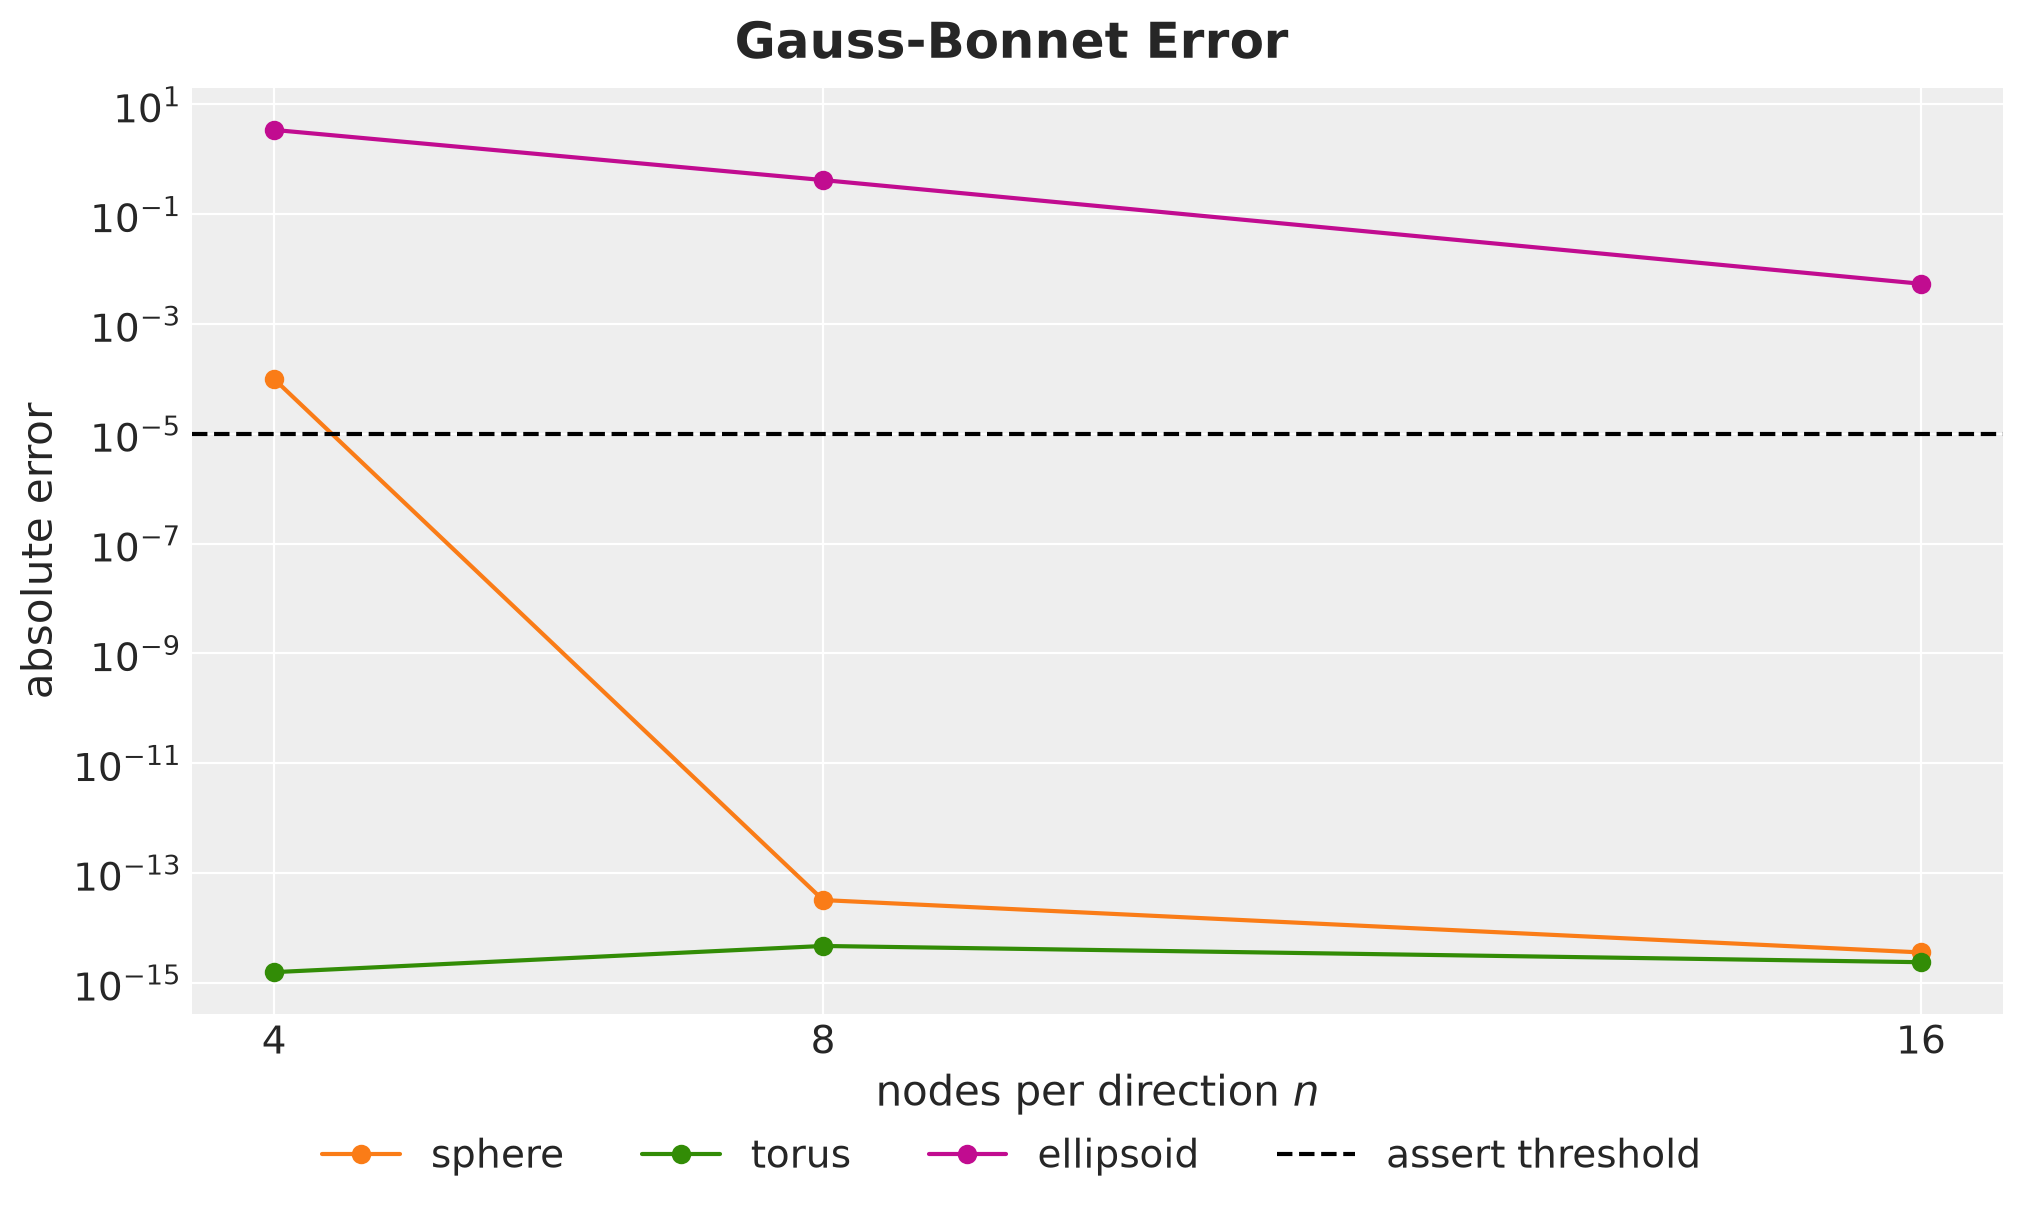

In [17]:
GB_TOLERANCE = 1e-5

fig, ax = plt.subplots(layout="constrained")

for name, color in SURFACE_COLORS.items():
    ax.plot(N_NODES, gauss_bonnet_errors[name], marker="o", color=color, label=name)

ax.axhline(GB_TOLERANCE, color="black", linestyle="--", label="assert threshold")
ax.set(
    yscale="log",
    xticks=N_NODES,
    xlabel="nodes per direction $n$",
    ylabel="absolute error",
)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Gauss-Bonnet Error", fontsize=18, fontweight="bold");

The three surfaces converge at different rates:

- **Sphere.** The error drops to round-off with $n = 8$ nodes per direction.
- **Torus.** The error stays at round-off for every $n$, as the midpoint rule predicts.
- **Ellipsoid.** The error falls by a constant factor per added node, a straight line on the log axis, which is geometric convergence. It needs more nodes than the sphere, which is consistent with its curvature being concentrated near the ends of its longest axis.

The ellipsoid is still above the threshold at $n = 16$. If we extend its line, it crosses the threshold before $n = 32$, so we check the theorem with $n = 32$ nodes per direction.

The left side is a quadrature, so it differs from $2 \pi \chi$ by a truncation error that shrinks with $n$. We check that both sides agree up to the absolute tolerance $10^{-5}$. The tolerance is absolute because the right side is $0$ for the torus.

With $n = 32$, the check needs $3072$ points in total ($3$ surfaces times $32^2 = 1024$ points), each with its own Riemann tensor:

In [18]:
%%time
for surface in surfaces.values():
    assert math.isclose(
        gb_curvature(surface, n_nodes=32),
        gb_euler_characteristic(surface),
        abs_tol=GB_TOLERANCE,
    )

CPU times: user 35.4 s, sys: 279 ms, total: 35.6 s
Wall time: 35.7 s


The two sides of the theorem agree for all three surfaces! The cell took about $36$ seconds for the $3072$ points, or about $12$ milliseconds per point.

We close with the lessons that carry over to other surfaces.

## Conclusion

### Key Findings

- **Agreement of both sides.** A tensor-product quadrature of $K \sqrt{\det g}$ converges geometrically to $2\pi\chi$ when each one-dimensional rule follows how its parameter direction closes up.
- **Pointwise checks of the curvature.** Closed forms and the extrinsic route check the nested derivatives of the intrinsic route at a few points, before any integral.
- **Little code per surface.** Given a base class that fixes the embedding space, an `immersion` method is enough for geomstats to derive the metric, the Christoffel symbols, and the Riemann tensor.

### Limitations

- Each surface needs one parametrization over a rectangle with periodic or pole closures. A surface of genus $2$ or more needs several charts or another description.
- Closed forms of $K$ exist only for special surfaces. On a general surface we can only compare the two routes with each other.
- The PyTorch backend differentiates point by point, so the cost grows linearly with the number of points, $n^2$ for $n$ nodes per direction. This is why we stop at $n = 32$.

### Recommendations

1. **Use geomstats from `main` with PyTorch.** The Riemann tensor of an `ImmersedSet` needs nested derivatives, which the PyTorch backend computes correctly only since [#2142](https://github.com/geomstats/geomstats/pull/2142).
2. **Check $K$ pointwise before integrating.** A closed form or the extrinsic route finds index and sign errors at a few points, before you pay for an integral.
3. **Match the quadrature to the closure.** Use the midpoint rule in periodic directions and Gauss-Legendre nodes in directions that end at poles, so that no node falls on a pole.

## Next Steps

1. **Boundary term.** On the cap $\theta \leq \theta_0$ of the unit sphere, the curvature term is $2\pi (1 - \cos\theta_0)$ and the boundary term is $2\pi \cos\theta_0$, which add up to $2\pi$, the value of $2\pi\chi$ for a disk. The geodesic curvature of a boundary curve follows from the Christoffel symbols that geomstats already computes.
2. **Discrete Gauss-Bonnet.** On a triangulated surface, the angle defect at a vertex plays the role of $K \, dA$, and the angle defects sum to $2\pi\chi$ exactly (see [Crane](https://www.cs.cmu.edu/~kmcrane/Projects/DDG/)). We could compare the angle defect divided by a vertex area with $K$ from geomstats on the same surfaces.
3. **Faster derivatives.** The loops over points in `jacobian_vec` and `hessian_vec` set the cost. Batching the nested derivatives with `torch.func.jacrev` and `torch.func.vmap` would remove the loops and make finer quadrature grids cheap.

## References

- Crane, K. [Discrete Differential Geometry: An Applied Introduction](https://www.cs.cmu.edu/~kmcrane/Projects/DDG/). Carnegie Mellon University.
- do Carmo, M. P. [Differential Geometry of Curves and Surfaces](https://store.doverpublications.com/products/9780486806990). Second edition, Dover.
- geomstats. [Fix nested autodiff in pytorch backend (wrong riemann_tensor on ImmersedSet)](https://github.com/geomstats/geomstats/pull/2142). Pull request #2142.
- Miolane, N., et al. [Geomstats: A Python Package for Riemannian Geometry in Machine Learning](https://jmlr.org/papers/v21/19-027.html). Journal of Machine Learning Research 21(223), 2020.
- Trefethen, L. N. [Is Gauss Quadrature Better than Clenshaw-Curtis?](https://doi.org/10.1137/060659831). SIAM Review 50(1), 2008.
- Trefethen, L. N., and Weideman, J. A. C. [The Exponentially Convergent Trapezoidal Rule](https://doi.org/10.1137/130932132). SIAM Review 56(3), 2014.
- Weisstein, E. W. [Ellipsoid](https://mathworld.wolfram.com/Ellipsoid.html). MathWorld.
- Wikipedia. [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem), [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium), [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic), [Betti number](https://en.wikipedia.org/wiki/Betti_number), [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula), [Gauss-Legendre quadrature](https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature).